In [1]:
import pandas as pd

df = pd.read_csv("/content/sample_data/Unemployment in India.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Shape: (768, 7)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [2]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe(include="all"))

Dataset Shape:
(768, 7)

Column Names:
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']

Data Types:
Region                                       object
 Date                                        object
 Frequency                                   object
 Estimated Unemployment Rate (%)            float64
 Estimated Employed                         float64
 Estimated Labour Participation Rate (%)    float64
Area                                         object
dtype: object

Missing Values:
Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unemployment Rate (%)            28
 Estimated Employed                         28
 Estimated Labour Participation Rate (%)    28
Area                                        28
dtype: int64

Duplicate Rows:
27

Statistical Summary:


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
count,740,740,740,740.000000,7.400000e+02,740.000000,740
unique,28,14,2,NaN,NaN,NaN,2
top,Andhra Pradesh,31-10-2019,Monthly,NaN,NaN,NaN,Urban
freq,28,55,381,NaN,NaN,NaN,381
mean,NaN,NaN,NaN,11.787946,7.204460e+06,42.630122,NaN
std,NaN,NaN,NaN,10.721298,8.087988e+06,8.111094,NaN
min,NaN,NaN,NaN,0.000000,4.942000e+04,13.330000,NaN
25%,NaN,NaN,NaN,4.657500,1.190404e+06,38.062500,NaN
50%,NaN,NaN,NaN,8.350000,4.744178e+06,41.160000,NaN
75%,NaN,NaN,NaN,15.887500,1.127549e+07,45.505000,NaN


In [3]:
df.columns = df.columns.str.strip()

df = df.drop_duplicates()

df = df.dropna(how="all")

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

print("Dataset cleaned successfully!")
print("Shape after cleaning:", df.shape)
print("\nMissing values after cleaning:")
print(df.isnull().sum())

Dataset cleaned successfully!
Shape after cleaning: (740, 7)

Missing values after cleaning:
Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Area                                       0
dtype: int64


In [4]:
print(df.columns.tolist())

['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area']


In [5]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce", dayfirst=True)

numeric_cols = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Data types after conversion:")
print(df.dtypes)

print("\nDate range:")
print(df["Date"].min(), "to", df["Date"].max())

print("\nMissing values after conversion:")
print(df.isnull().sum())


Data types after conversion:
Region                                             object
Date                                       datetime64[ns]
Frequency                                          object
Estimated Unemployment Rate (%)                   float64
Estimated Employed                                float64
Estimated Labour Participation Rate (%)           float64
Area                                               object
dtype: object

Date range:
2019-05-31 00:00:00 to 2020-06-30 00:00:00

Missing values after conversion:
Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Area                                       0
dtype: int64


In [6]:
region_unemployment = df.groupby("Region")["Estimated Unemployment Rate (%)"].mean().sort_values(ascending=False)

display(region_unemployment.reset_index(name="Average Unemployment Rate (%)"))


,Region,Average Unemployment Rate (%)
0,Tripura,28.350357
1,Haryana,26.283214
2,Jharkhand,20.585000
3,Bihar,18.918214
4,Himachal Pradesh,18.540357
5,Delhi,16.495357
6,Jammu & Kashmir,16.188571
7,Chandigarh,15.991667
8,Rajasthan,14.058214
9,Uttar Pradesh,12.551429


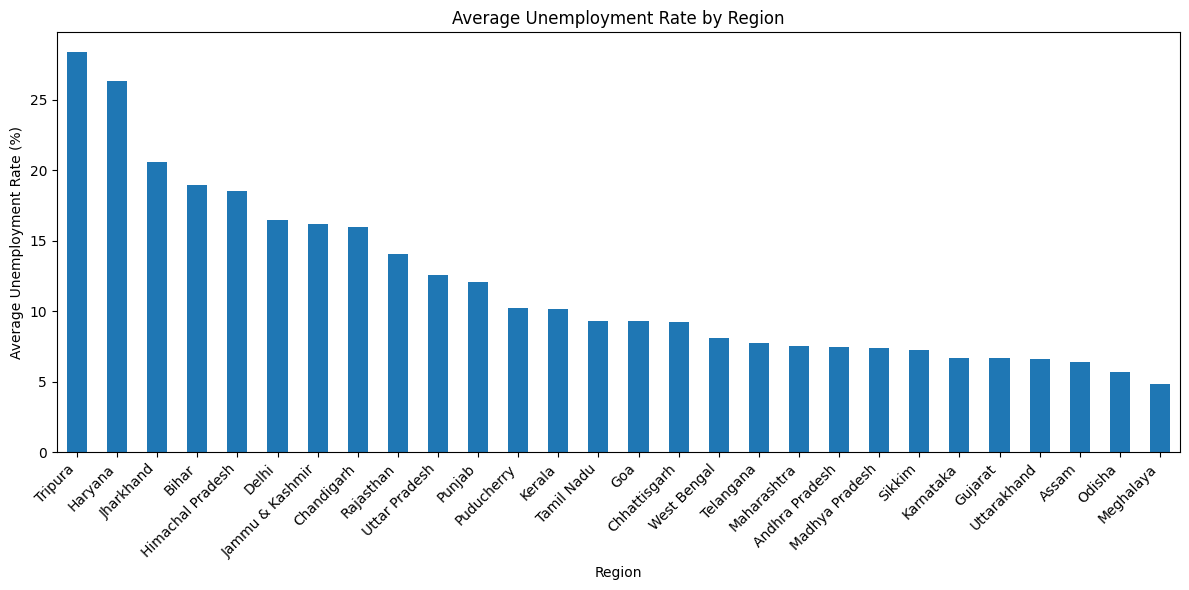

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
region_unemployment.plot(kind="bar")
plt.title("Average Unemployment Rate by Region")
plt.xlabel("Region")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [9]:
monthly_unemployment = df.groupby(
    df["Date"].dt.to_period("M")
)["Estimated Unemployment Rate (%)"].mean()

display(monthly_unemployment.reset_index())

,Date,Estimated Unemployment Rate (%)
0,2019-05,8.874259
1,2019-06,9.303333
2,2019-07,9.033889
3,2019-08,9.637925
4,2019-09,9.051731
5,2019-10,9.900909
6,2019-11,9.868364
7,2019-12,9.497358
8,2020-01,9.950755
9,2020-02,9.964717


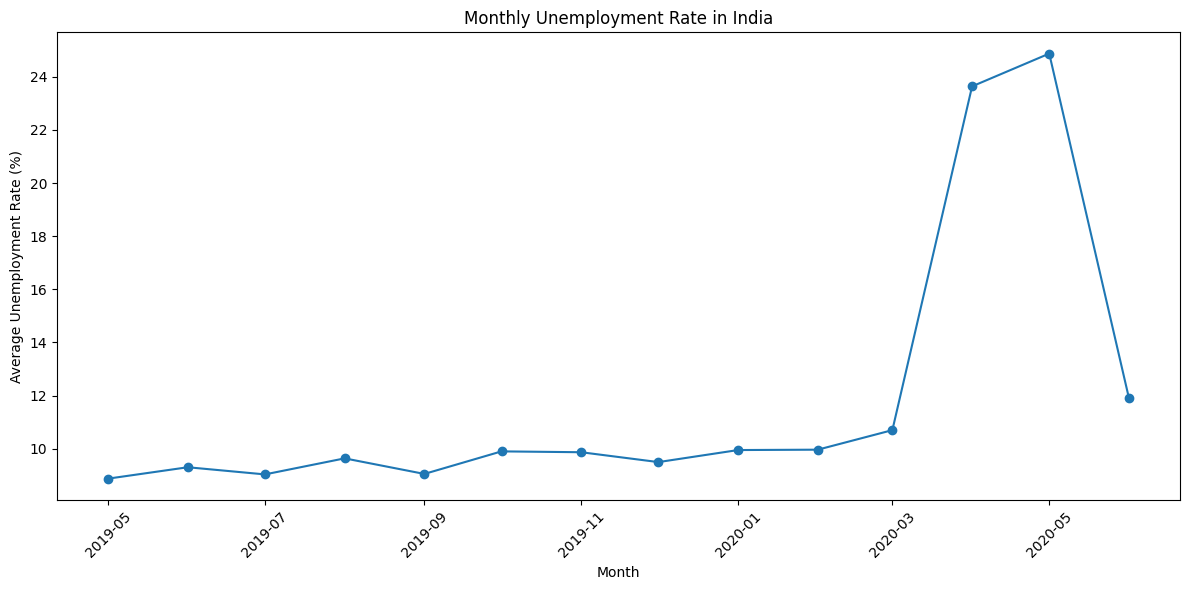

In [10]:
plt.figure(figsize=(12, 6))
monthly_unemployment.index = monthly_unemployment.index.to_timestamp()
plt.plot(monthly_unemployment.index, monthly_unemployment.values, marker="o")
plt.title("Monthly Unemployment Rate in India")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [11]:
pre_covid = df[df["Date"] < "2020-03-01"]
post_covid = df[df["Date"] >= "2020-03-01"]

pre_covid_rate = pre_covid["Estimated Unemployment Rate (%)"].mean()
post_covid_rate = post_covid["Estimated Unemployment Rate (%)"].mean()

print("Average Unemployment Rate Before COVID-19:", round(pre_covid_rate, 2), "%")
print("Average Unemployment Rate From March 2020 Onward:", round(post_covid_rate, 2), "%")

Average Unemployment Rate Before COVID-19: 9.51 %
Average Unemployment Rate From March 2020 Onward: 17.77 %


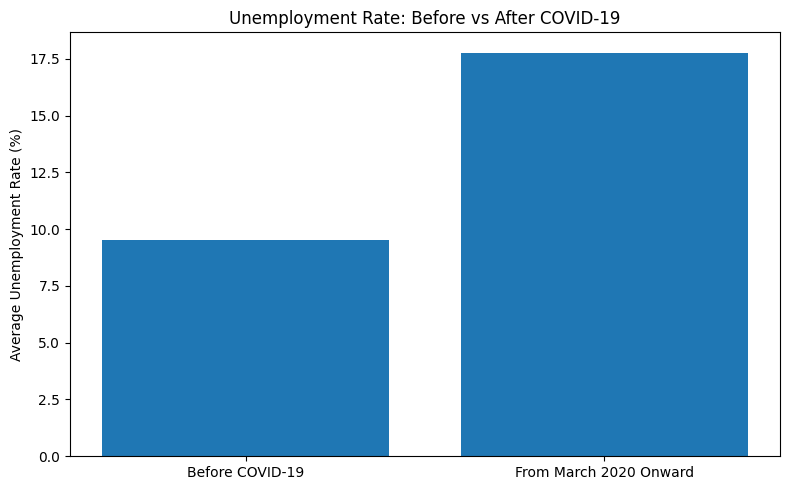

In [12]:
plt.figure(figsize=(8, 5))

plt.bar(
    ["Before COVID-19", "From March 2020 Onward"],
    [pre_covid_rate, post_covid_rate]
)

plt.title("Unemployment Rate: Before vs After COVID-19")
plt.ylabel("Average Unemployment Rate (%)")
plt.tight_layout()
plt.show()

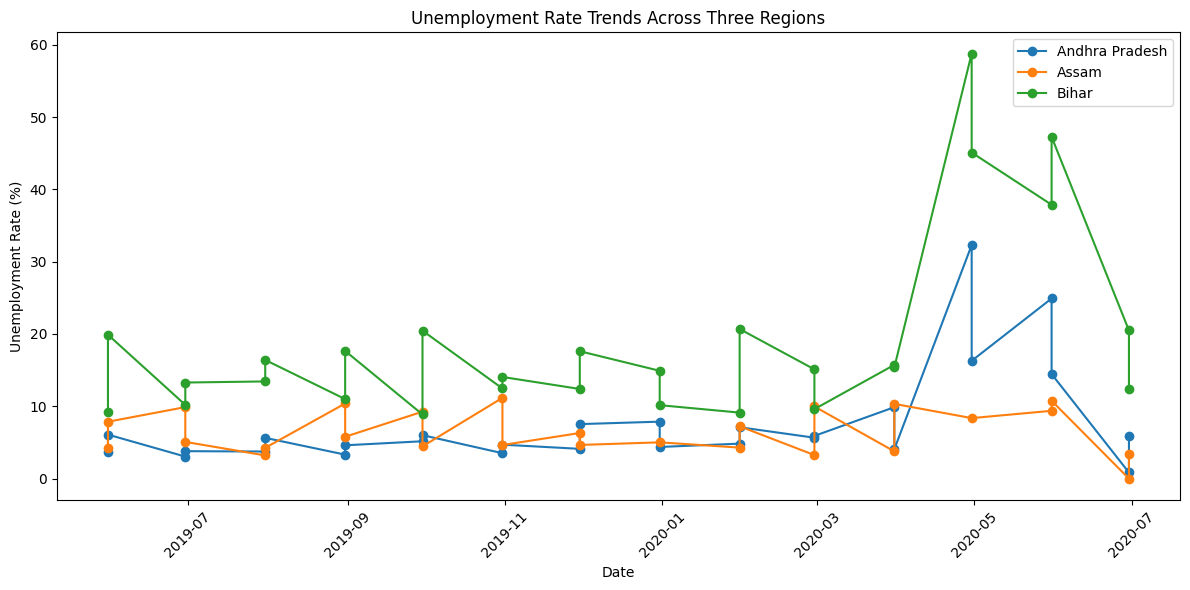

In [13]:
top_regions = df["Region"].dropna().unique()[:3]

plt.figure(figsize=(12, 6))

for region in top_regions:
    region_data = df[df["Region"] == region].sort_values("Date")
    plt.plot(
        region_data["Date"],
        region_data["Estimated Unemployment Rate (%)"],
        marker="o",
        label=region
    )

plt.title("Unemployment Rate Trends Across Three Regions")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [14]:
top_10_regions = df.groupby("Region")[
    "Estimated Unemployment Rate (%)"
].mean().sort_values(ascending=False).head(10)

display(top_10_regions.reset_index(name="Average Unemployment Rate (%)"))

,Region,Average Unemployment Rate (%)
0,Tripura,28.350357
1,Haryana,26.283214
2,Jharkhand,20.585000
3,Bihar,18.918214
4,Himachal Pradesh,18.540357
5,Delhi,16.495357
6,Jammu & Kashmir,16.188571
7,Chandigarh,15.991667
8,Rajasthan,14.058214
9,Uttar Pradesh,12.551429


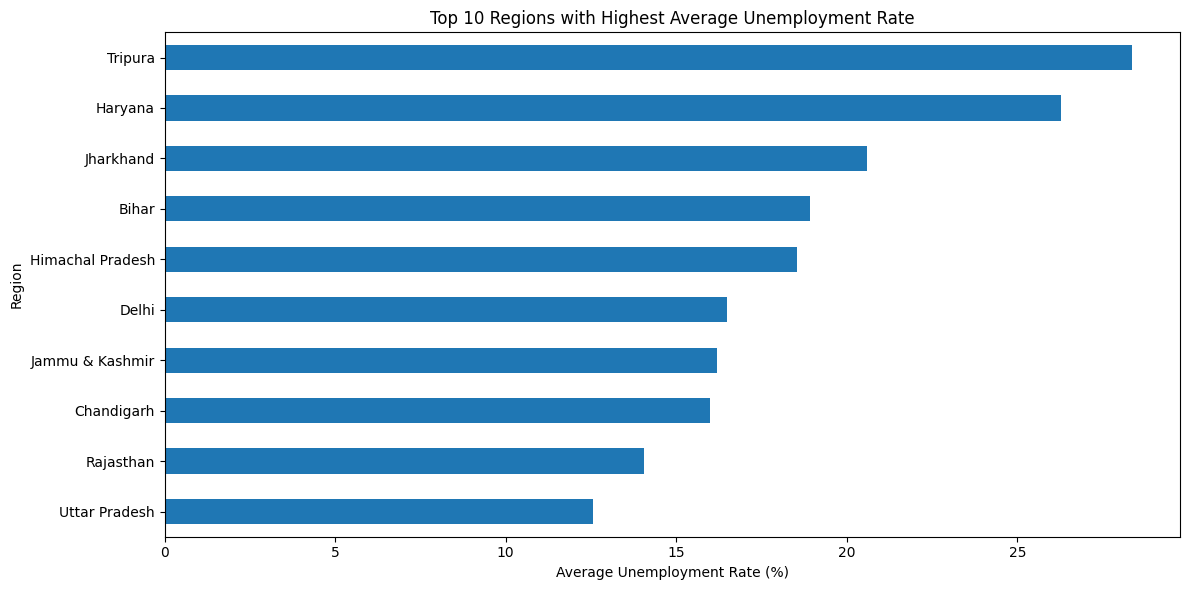

In [15]:
plt.figure(figsize=(12, 6))

top_10_regions.sort_values().plot(kind="barh")

plt.title("Top 10 Regions with Highest Average Unemployment Rate")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

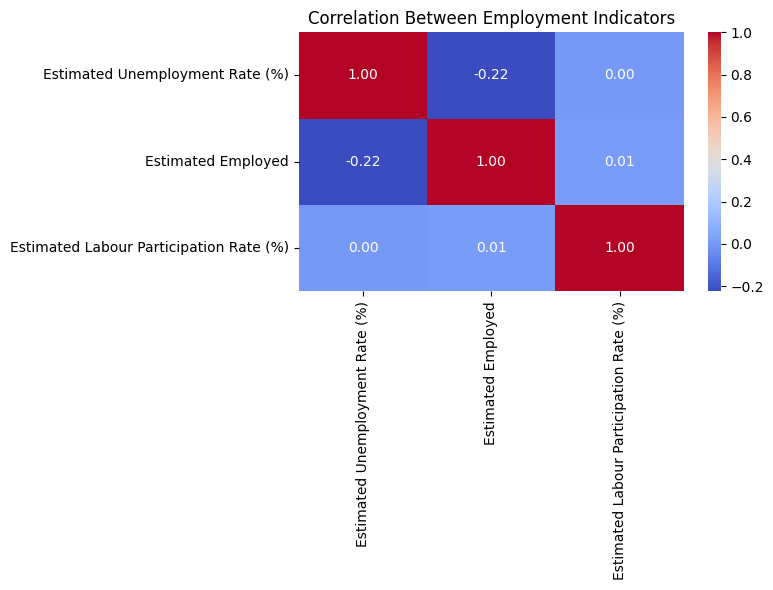

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

correlation_data = df[
    [
        "Estimated Unemployment Rate (%)",
        "Estimated Employed",
        "Estimated Labour Participation Rate (%)"
    ]
].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_data, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Employment Indicators")
plt.tight_layout()
plt.show()

## Key Observations

1. **Regional Analysis:** The average unemployment rate varies across regions, indicating differences in regional employment conditions.
2. **Monthly Trends:** The monthly trend chart shows how unemployment rates change over time.
3. **COVID-19 Impact:** Comparing the periods before and from March 2020 onward helps examine changes in unemployment rates during the pandemic and subsequent period.
4. **Regional Comparison:** The time-series chart compares unemployment trends across three selected regions.
5. **Top 10 Regions:** The bar chart identifies the regions with the highest average unemployment rates in the dataset.
6. **Correlation Analysis:** The heatmap shows the strength and direction of the relationships between unemployment, employment, and labour participation rates.

## Conclusion

This project analyzes unemployment patterns in India using Python and data visualization. Exploratory data analysis was used to examine regional differences, monthly trends, and changes around the COVID-19 period. Bar charts, line charts, and a correlation heatmap helped summarize the dataset and identify patterns in the employment indicators.